# Bark Classification — ResNet50 × 3 Seeds (42, 123, 2026)

ปรับจาก `ResNet50.ipynb` โดยคงแนวทางโมเดลเดิม: ResNet50 pretrained ImageNet, freeze backbone, ใช้ `avg_pool` เป็น feature extractor, Dense 15 คลาส, Adam, categorical cross-entropy, input 224×224, batch size 16, 20 epochs

รูปแบบการเก็บผลลัพธ์ต่อยอดตาม `Bark_SwinT_DeiTS_MultiSeed`:
- seed เทรน: `42, 123, 2026`; split train/validation คงที่ด้วย seed 42
- test set ต้องมี 795 ภาพ (15 คลาส × 53 ภาพ) และใช้ชุดเดิมทุก seed
- confusion matrix แยกแต่ละ seed, Precision/Recall/F1 รายคลาสและ Macro-F1/Accuracy ราย seed
- CSV prediction รายภาพพร้อม Image ID, True Label, ResNet50 Prediction ของแต่ละ seed
- McNemar's test เปรียบเทียบผลทำนายของ seed เป็นคู่ บน test set เดียวกัน
- เก็บ Mean และ sample SD (ddof=1) ของ Macro-F1 และ Accuracy เป็น CSV แยก พร้อมไฟล์สรุปค่าเดิมอื่น ๆ

**สำคัญ:** ผลยังไม่ถูกสร้างจนกว่าจะรัน notebook ครบทุกเซลล์ใน Colab. ตรวจสอบ path หลังดาวน์โหลดว่าโฟลเดอร์อยู่ตรงตามที่ระบุด้านล่าง

## 0. ติดตั้งและตั้งค่า

In [ ]:
!pip -q install split-folders scipy scikit-learn seaborn openpyxl

import os, random, time, json, shutil, hashlib, itertools, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import splitfolders
from scipy.stats import binomtest, chi2
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, matthews_corrcoef, confusion_matrix,
    classification_report
)

SEEDS = [42, 123, 2026]
SPLIT_SEED = 42                 # คงที่ ไม่เปลี่ยนตาม seed เทรน
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 20
MCNEMAR_ALPHA = 0.05
TEST_EXPECTED = 795
RESULTS_DIR = Path('/content/ResNet50_Bark_results_multiseed')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_VAL_SOURCE = Path('/content/dataset/Plant/Bark_runModel/Bark_runModel')
TEST_SOURCE = Path('/content/Bark_Test_53_Final/Bark_Test_53_Final')
SPLIT_DIR = Path('/content/split_dataset')

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))
print('Output:', RESULTS_DIR)

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Output: /content/ResNet50_Bark_results_multiseed


## 1. ดาวน์โหลด dataset (ถ้ายังไม่มีใน runtime)

In [ ]:
# ใช้แหล่งข้อมูลเดิมจาก ResNet50.ipynb
ku_download_url = "https://kudrive.ku.ac.th/public.php/dav/files/LgrKQKSD3tpaE78/Bark_runModel/?accept=zip"
ku_test_url = "https://kudrive.ku.ac.th/public.php/dav/files/LgrKQKSD3tpaE78/Bark_Test_53_Final/?accept=zip"

if not TRAIN_VAL_SOURCE.is_dir():
    !wget -q -O /content/Bark_runModel.zip "{ku_download_url}"
    !mkdir -p /content/dataset/Plant/Bark_runModel
    !unzip -q /content/Bark_runModel.zip -d /content/dataset/Plant/Bark_runModel/

if not TEST_SOURCE.is_dir():
    !wget -q -O /content/Bark_Test_53_Final.zip "{ku_test_url}"
    !mkdir -p /content/Bark_Test_53_Final
    !unzip -q /content/Bark_Test_53_Final.zip -d /content/Bark_Test_53_Final/

assert TRAIN_VAL_SOURCE.is_dir(), f'ไม่พบ {TRAIN_VAL_SOURCE}'
assert TEST_SOURCE.is_dir(), f'ไม่พบ {TEST_SOURCE}'
print('Train/Val source:', TRAIN_VAL_SOURCE)
print('Test source:', TEST_SOURCE)

Train/Val source: /content/dataset/Plant/Bark_runModel/Bark_runModel
Test source: /content/Bark_Test_53_Final/Bark_Test_53_Final


## 2. สร้าง split คงที่และ manifest ของ Test 795 ภาพ

In [ ]:
# ลบ split เดิมเพื่อให้ split ที่สร้างด้วย seed 42 ถูกต้องและทำซ้ำได้
if SPLIT_DIR.exists():
    shutil.rmtree(SPLIT_DIR)
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

splitfolders.fixed(
    str(TRAIN_VAL_SOURCE), output=str(SPLIT_DIR),
    seed=SPLIT_SEED, fixed=(53,), oversample=False, group_prefix=None
)
SPLIT_TEST_DIR = SPLIT_DIR / 'test'
if SPLIT_TEST_DIR.exists():
    shutil.rmtree(SPLIT_TEST_DIR)
shutil.copytree(TEST_SOURCE, SPLIT_TEST_DIR)

IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
CLASS_NAMES = sorted([p.name for p in (SPLIT_DIR/'train').iterdir() if p.is_dir()])
NUM_CLASSES = len(CLASS_NAMES)
assert NUM_CLASSES == 15, f'คาดหวัง 15 คลาส แต่พบ {NUM_CLASSES}: {CLASS_NAMES}'

def md5sum(path):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

test_rows = []
for label, cls in enumerate(CLASS_NAMES):
    folder = SPLIT_TEST_DIR / cls
    if not folder.is_dir():
        raise FileNotFoundError(f'ไม่พบ test class folder: {folder}')
    for p in sorted([p for p in folder.iterdir() if p.is_file() and p.suffix.lower() in IMG_EXTS],
                    key=lambda p: p.name.casefold()):
        test_rows.append({
            'class_name': cls, 'label': label, 'file_name': p.name,
            'local_path': str(p), 'md5': md5sum(p)
        })
test_rows.sort(key=lambda r: (r['label'], r['file_name'].casefold()))
width = max(3, len(str(len(test_rows))))
for i, row in enumerate(test_rows, 1):
    row['image_id'] = f'img{i:0{width}d}'
TEST_MANIFEST = pd.DataFrame(test_rows)
assert len(TEST_MANIFEST) == TEST_EXPECTED, (
    f'Test set ต้องมี {TEST_EXPECTED} ภาพ แต่พบ {len(TEST_MANIFEST)} ภาพ. '
    'ตรวจสอบโฟลเดอร์ test และจำนวนภาพต่อคลาสก่อนรันต่อ'
)
assert TEST_MANIFEST['image_id'].is_unique
TEST_MANIFEST[['image_id','class_name','file_name','local_path','md5']].to_csv(
    RESULTS_DIR/'02_test_manifest.csv', index=False, encoding='utf-8-sig'
)

split_rows=[]
for split in ['train','val','test']:
    for cls in CLASS_NAMES:
        folder=SPLIT_DIR/split/cls
        n=sum(1 for p in folder.iterdir() if p.is_file() and p.suffix.lower() in IMG_EXTS)
        split_rows.append({'Split':split,'Class':cls,'Images':n})
df_split=pd.DataFrame(split_rows)
display(df_split.pivot(index='Class',columns='Split',values='Images'))
df_split.to_csv(RESULTS_DIR/'01_dataset_split_counts.csv',index=False,encoding='utf-8-sig')
print('Classes:', CLASS_NAMES)
print('Test images:', len(TEST_MANIFEST))

Copying files: 4500 files [00:13, 335.62 files/s]


Split,test,train,val
Class,,,
Alstonia scholaris,53,247,53
Cassia fistula,53,247,53
Delonix regia,53,247,53
Dipterocarpus alatus Roxb,53,247,53
Lagerstroemia duperreana,53,247,53
Lagerstroemia loudonii,53,247,53
Lagerstroemia macrocarpa,53,247,53
Peltophorum dasyrhachis,53,247,53
Peltophorum pterocarpum,53,247,53


Classes: ['Alstonia scholaris', 'Cassia fistula', 'Delonix regia', 'Dipterocarpus alatus Roxb', 'Lagerstroemia duperreana', 'Lagerstroemia loudonii', 'Lagerstroemia macrocarpa', 'Peltophorum dasyrhachis', 'Peltophorum pterocarpum', 'Pterocarpus indicus', 'Pterocarpus macrocarpus', 'Streblus asper', 'Swietenia macrophylla', 'Tectona grandis', 'Triplaris cumingiana Fisch']
Test images: 795


## 3. Data pipeline และโมเดล ResNet50 ตามโค้ดเดิม

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def load_dataset(split, shuffle=False, seed=None):
    ds = tf.keras.utils.image_dataset_from_directory(
        str(SPLIT_DIR / split), image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        label_mode='categorical', shuffle=shuffle, seed=seed,
        class_names=CLASS_NAMES
    )
    return ds.prefetch(AUTOTUNE)

train_ds_base = load_dataset('train', shuffle=False)
val_ds = load_dataset('val', shuffle=False)

# สร้าง Test dataset จาก manifest โดยตรง เพื่อให้ลำดับ prediction ตรงกับ Image ID ใน CSV
def decode_test_image(path, label):
    raw = tf.io.read_file(path)
    image = tf.image.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    label = tf.one_hot(label, depth=NUM_CLASSES)
    return image, label

test_paths = TEST_MANIFEST['local_path'].astype(str).to_numpy()
test_labels = TEST_MANIFEST['label'].astype(np.int32).to_numpy()
test_ds = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_ds = test_ds.map(decode_test_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

# ตรวจว่า class order ตรงกับโฟลเดอร์ train
train_class_dirs = {p.name for p in (SPLIT_DIR / 'train').iterdir() if p.is_dir()}
assert set(CLASS_NAMES) == train_class_dirs, f"CLASS_NAMES ไม่ตรงกับโฟลเดอร์ train: CLASS_NAMES={CLASS_NAMES}, folders={sorted(train_class_dirs)}"

y_true = np.array(TEST_MANIFEST['label'].tolist(), dtype=np.int64)
assert len(y_true) == TEST_EXPECTED

def set_seed(seed):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)
    try:
        tf.config.experimental.enable_op_determinism()
    except Exception:
        pass

def build_resnet50():
    # Pretrained ImageNet, freeze backbone, ใช้ avg_pool feature extractor และ Dense ใหม่
    base_resnet = tf.keras.applications.ResNet50(
        include_top=True, weights='imagenet', classifier_activation='softmax'
    )
    for layer in base_resnet.layers:
        layer.trainable = False
    feature_extractor = tf.keras.Model(
        inputs=base_resnet.input,
        outputs=base_resnet.get_layer('avg_pool').output,
        name='resnet50_feature_extractor'
    )
    inputs = tf.keras.Input(shape=(224, 224, 3), name='input_224')
    x = tf.keras.applications.resnet50.preprocess_input(inputs)
    features = feature_extractor(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax', name='bark_predictions')(features)
    model = tf.keras.Model(inputs=inputs, outputs=outputs, name='ResNet50_Bark_Classifier_15Classes')
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

print('Train batches:', tf.data.experimental.cardinality(train_ds_base).numpy())
print('Val batches:', tf.data.experimental.cardinality(val_ds).numpy())
print('Test batches:', tf.data.experimental.cardinality(test_ds).numpy())

Found 3705 files belonging to 15 classes.
Found 795 files belonging to 15 classes.
Train batches: 232
Val batches: 50
Test batches: 50


## 4. เทรนและประเมินผล 3 seeds


ResNet50 | seed 42
Found 3705 files belonging to 15 classes.
102967424/102967424 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Epoch 1/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 31s 98ms/step - accuracy: 0.8834 - loss: 0.4626 - val_accuracy: 0.9585 - val_loss: 0.1539
Epoch 2/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 21s 91ms/step - accuracy: 0.9827 - loss: 0.0973 - val_accuracy: 0.9799 - val_loss: 0.0868
Epoch 3/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 22s 93ms/step - accuracy: 0.9922 - loss: 0.0537 - val_accuracy: 0.9824 - val_loss: 0.0656
Epoch 4/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 22s 95ms/step - accuracy: 0.9962 - loss: 0.0355 - val_accuracy: 0.9862 - val_loss: 0.0542
Epoch 5/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 22s 95ms/step - accuracy: 0.9987 - loss: 0.0253 - val_accuracy: 0.9862 - val_loss: 0.0510
Epoch 6/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 22s 93ms/step - accuracy: 0.9989 - loss: 0.0184 - val_accuracy: 0.9899 - val_loss: 0.0426
Epoch 7/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 22s 94ms/step - accuracy: 0.9995 - loss: 0.0143 - val_accuracy: 0

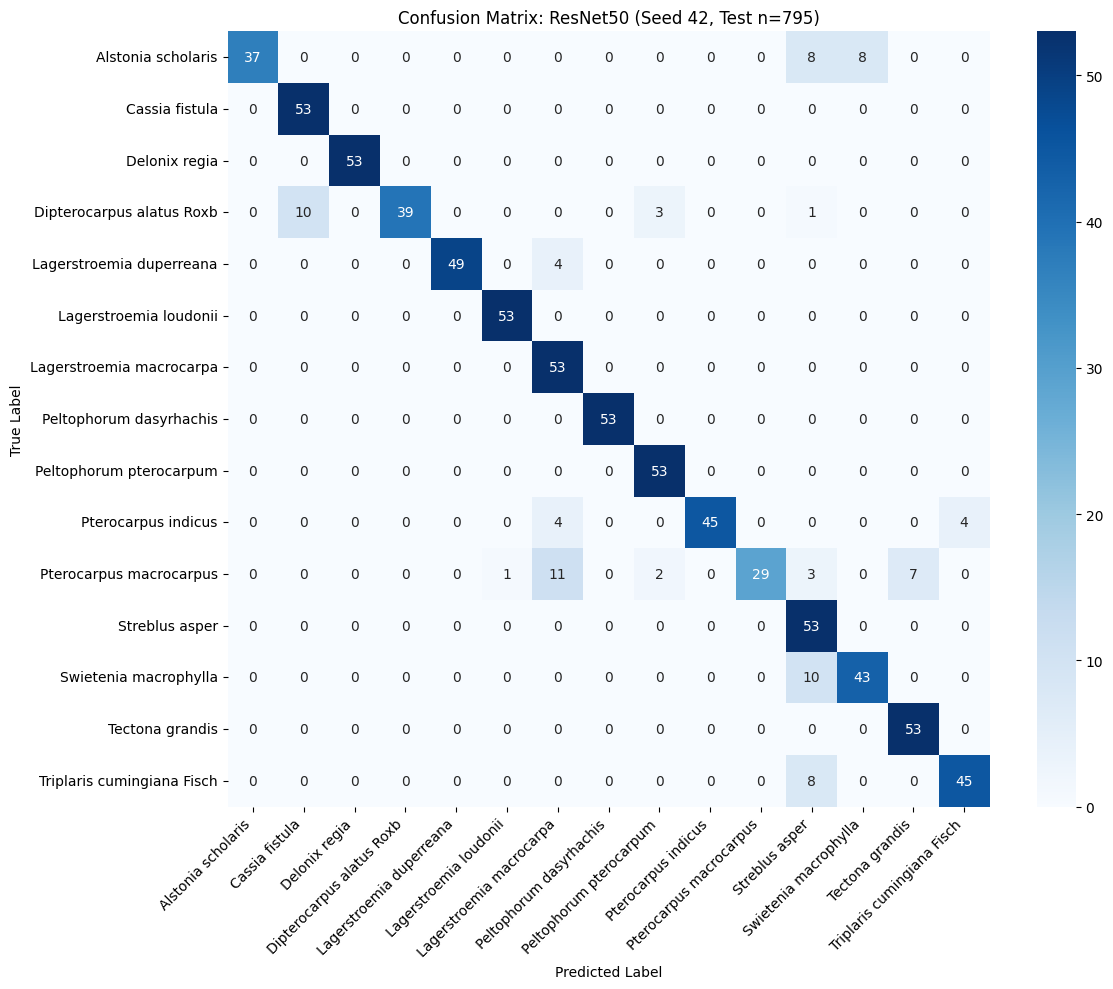

Architecture                  ResNet50
Seed                                42
Macro-F1 (%)                 89.271068
Accuracy (%)                 89.433962
Macro-Precision (%)          91.706985
Macro-Recall (%)             89.433962
Weighted-F1 (%)              89.271068
AUC OvR macro (%)            99.500246
MCC (%)                      88.872601
Test n                             795
Epochs run                          20
Training time (min)           7.427782
Training time (sec)         445.666934
Inference time (sec)          7.078233
Test loss                     0.588346
Total parameters              23618447
Trainable parameters             30735
Non-trainable parameters      23587712

ResNet50 | seed 123
Found 3705 files belonging to 15 classes.
Epoch 1/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 30s 103ms/step - accuracy: 0.8669 - loss: 0.5298 - val_accuracy: 0.9660 - val_loss: 0.1550
Epoch 2/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 22s 95ms/step - accuracy: 0.9784 - loss: 0.1031 - val_accuracy: 

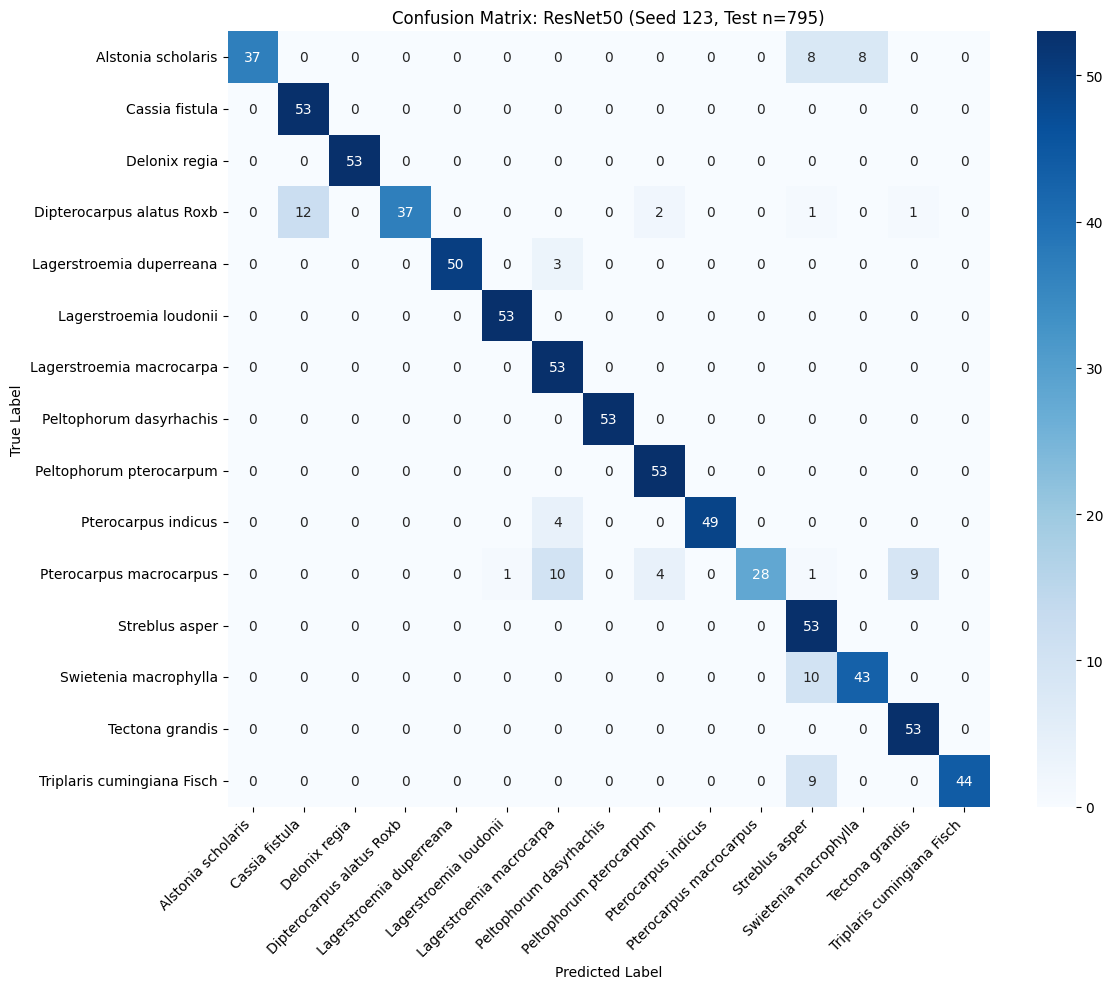

Architecture                  ResNet50
Seed                               123
Macro-F1 (%)                 89.318366
Accuracy (%)                 89.559748
Macro-Precision (%)          91.887084
Macro-Recall (%)             89.559748
Weighted-F1 (%)              89.318366
AUC OvR macro (%)            99.500246
MCC (%)                       89.01479
Test n                             795
Epochs run                          20
Training time (min)           7.431943
Training time (sec)         445.916577
Inference time (sec)          7.123483
Test loss                     0.595022
Total parameters              23618447
Trainable parameters             30735
Non-trainable parameters      23587712

ResNet50 | seed 2026
Found 3705 files belonging to 15 classes.
Epoch 1/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 30s 103ms/step - accuracy: 0.8702 - loss: 0.4988 - val_accuracy: 0.9597 - val_loss: 0.1681
Epoch 2/20
232/232 ━━━━━━━━━━━━━━━━━━━━ 22s 96ms/step - accuracy: 0.9789 - loss: 0.1049 - val_accuracy:

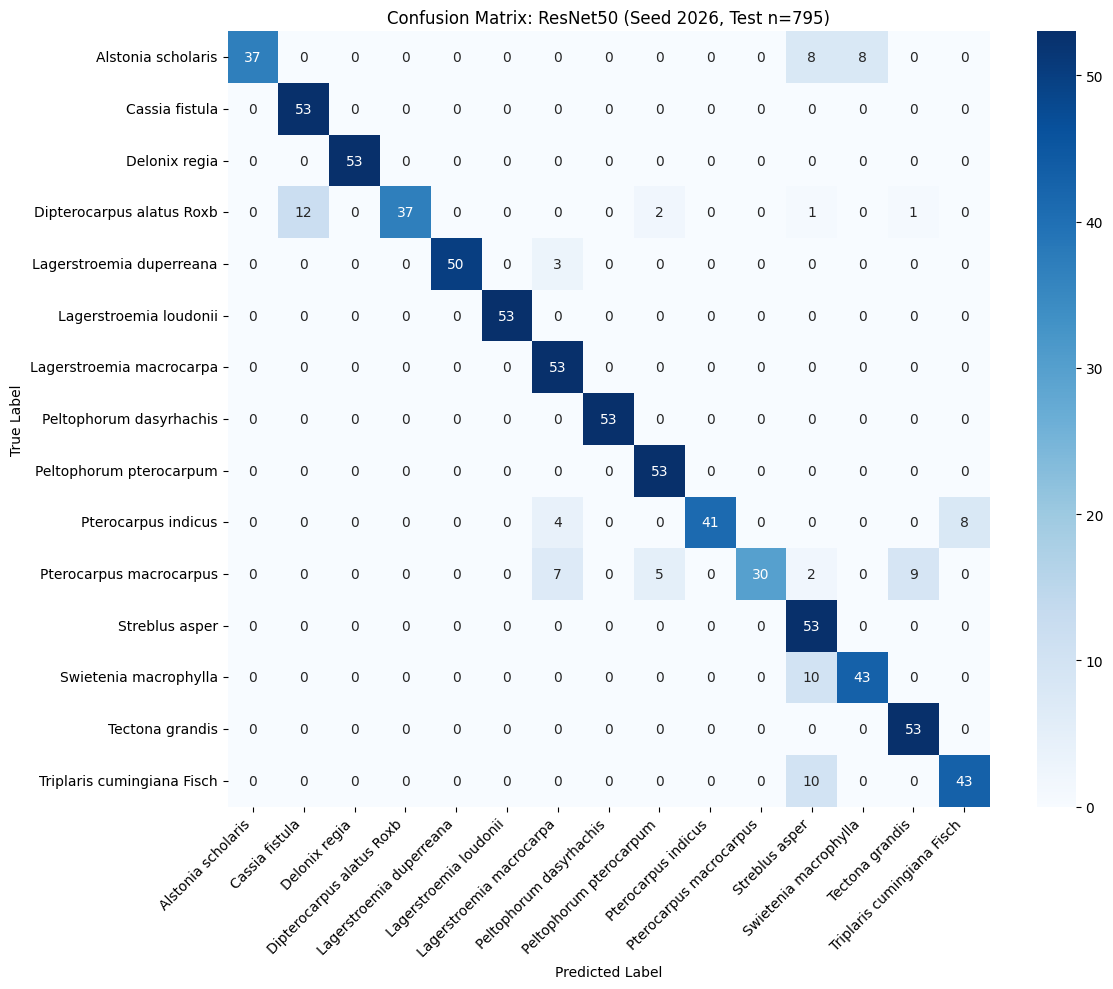

Architecture                 ResNet50
Seed                             2026
Macro-F1 (%)                88.477357
Accuracy (%)                88.679245
Macro-Precision (%)         90.988396
Macro-Recall (%)            88.679245
Weighted-F1 (%)             88.477357
AUC OvR macro (%)           99.354117
MCC (%)                     88.068811
Test n                            795
Epochs run                         20
Training time (min)           7.45117
Training time (sec)          447.0702
Inference time (sec)         7.070885
Test loss                    0.655861
Total parameters             23618447
Trainable parameters            30735
Non-trainable parameters     23587712


In [ ]:
RESULTS = {}
HISTORIES = {}
PREDICTIONS = {}

def plot_confusion_matrix(cm, seed):
    fig, ax = plt.subplots(figsize=(12,10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set_title(f'Confusion Matrix: ResNet50 (Seed {seed}, Test n={len(y_true)})')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    fig.savefig(RESULTS_DIR/f'CM_ResNet50_seed{seed}.png', dpi=250, bbox_inches='tight')
    plt.show()
    plt.close(fig)

for seed in SEEDS:
    run_dir = RESULTS_DIR / 'runs' / f'seed{seed}'
    run_dir.mkdir(parents=True, exist_ok=True)
    model_path = run_dir / f'ResNet50_seed{seed}.keras'
    history_path = run_dir / f'training_history_seed{seed}.csv'

    print('\n' + '='*80 + f'\nResNet50 | seed {seed}\n' + '='*80)
    tf.keras.backend.clear_session()
    set_seed(seed)
    # shuffle train order แตกต่างตาม seed; train/validation split ยังคงเดิม
    train_ds = load_dataset('train', shuffle=True, seed=seed)
    model = build_resnet50()
    total_params = int(model.count_params())
    trainable_params = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    non_trainable_params = int(sum(np.prod(w.shape) for w in model.non_trainable_weights))

    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, verbose=1)
    training_time = time.time() - start
    hist_df = pd.DataFrame(history.history)
    hist_df.index = hist_df.index + 1
    hist_df.index.name = 'Epoch'
    hist_df.reset_index().to_csv(history_path, index=False, encoding='utf-8-sig')
    model.save(model_path)

    start_inf = time.time()
    prob = model.predict(test_ds, verbose=1)
    infer_time = time.time() - start_inf
    pred = np.argmax(prob, axis=1)
    assert len(pred) == len(TEST_MANIFEST) == len(y_true)

    cm = confusion_matrix(y_true, pred, labels=list(range(NUM_CLASSES)))
    report_dict = classification_report(
        y_true, pred, labels=list(range(NUM_CLASSES)), target_names=CLASS_NAMES,
        output_dict=True, zero_division=0
    )
    report = pd.DataFrame(report_dict).T
    report.index.name = 'Class'
    report.to_csv(run_dir/f'classification_report_ResNet50_seed{seed}.csv', encoding='utf-8-sig')
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).rename_axis('True Label').to_csv(
        run_dir/f'confusion_matrix_ResNet50_seed{seed}.csv', encoding='utf-8-sig'
    )

    metrics = {
        'Architecture':'ResNet50', 'Seed':seed,
        'Macro-F1 (%)':100*f1_score(y_true,pred,average='macro',zero_division=0),
        'Accuracy (%)':100*accuracy_score(y_true,pred),
        'Macro-Precision (%)':100*precision_score(y_true,pred,average='macro',zero_division=0),
        'Macro-Recall (%)':100*recall_score(y_true,pred,average='macro',zero_division=0),
        'Weighted-F1 (%)':100*f1_score(y_true,pred,average='weighted',zero_division=0),
        'AUC OvR macro (%)':100*roc_auc_score(
            tf.keras.utils.to_categorical(y_true,NUM_CLASSES), prob,
            multi_class='ovr', average='macro'
        ),
        'MCC (%)':100*matthews_corrcoef(y_true,pred),
        'Test n':len(y_true), 'Epochs run':len(hist_df),
        'Training time (min)':training_time/60, 'Training time (sec)':training_time,
        'Inference time (sec)':infer_time, 'Test loss':float(model.evaluate(test_ds,verbose=0)[0]),
        'Total parameters':total_params, 'Trainable parameters':trainable_params,
        'Non-trainable parameters':non_trainable_params
    }
    pd.DataFrame([metrics]).to_csv(RESULTS_DIR/f'06_results_seed{seed}.csv',index=False,encoding='utf-8-sig')
    pred_df = pd.DataFrame({
        'Image ID':TEST_MANIFEST['image_id'],
        'True Label':TEST_MANIFEST['class_name'],
        'ResNet50 Prediction': [CLASS_NAMES[i] for i in pred]
    })
    pred_df.to_csv(RESULTS_DIR/f'08_predictions_seed{seed}.csv',index=False,encoding='utf-8-sig')
    PREDICTIONS[seed] = pred
    RESULTS[seed] = {'metrics':metrics,'cm':cm,'report':report,'prob':prob,'pred':pred,
                     'history':hist_df,'training_time':training_time}
    plot_confusion_matrix(cm,seed)
    print(pd.Series(metrics).to_string())

## 5. รวมผลราย seed, Mean และ SD (CSV แยก)

In [ ]:
assert set(RESULTS) == set(SEEDS), f'ผลไม่ครบทุก seed: {list(RESULTS)}'
df_seed = pd.DataFrame([RESULTS[s]['metrics'] for s in SEEDS])
df_seed.to_csv(RESULTS_DIR/'06_results_per_seed.csv',index=False,encoding='utf-8-sig')
display(df_seed)

# เก็บ Macro-F1 และ Accuracy เป็นไฟล์ Mean/SD แยกตามที่กำหนด
main_metrics = ['Macro-F1 (%)','Accuracy (%)']
mean_sd_rows=[]
for metric in main_metrics:
    vals = np.array([RESULTS[s]['metrics'][metric] for s in SEEDS], dtype=float)
    mean_sd_rows.append({
        'Metric':metric, 'Seed 42':vals[0], 'Seed 123':vals[1], 'Seed 2026':vals[2],
        'Mean':float(np.mean(vals)), 'SD':float(np.std(vals,ddof=1)), 'N seeds':len(vals),
        'SD type':'Sample SD (ddof=1)'
    })
df_mean_sd = pd.DataFrame(mean_sd_rows)
df_mean_sd.to_csv(RESULTS_DIR/'07_summary_mean_sd.csv',index=False,encoding='utf-8-sig')
display(df_mean_sd)

# ค่าเฉลี่ย ± SD ของ metrics อื่น ๆ เพิ่มเติม โดยไม่แทนที่ไฟล์เดิม
extra_metrics = ['Macro-Precision (%)','Macro-Recall (%)','Weighted-F1 (%)','AUC OvR macro (%)','MCC (%)']
all_mean_sd=[]
for metric in main_metrics + extra_metrics:
    vals=np.array([RESULTS[s]['metrics'][metric] for s in SEEDS],dtype=float)
    all_mean_sd.append({'Metric':metric,'Mean (%)':vals.mean(),'SD (%)':vals.std(ddof=1),
                        'N seeds':len(vals),'SD type':'Sample SD (ddof=1)'})
pd.DataFrame(all_mean_sd).to_csv(RESULTS_DIR/'07b_summary_mean_sd_all_metrics.csv',index=False,encoding='utf-8-sig')

,Architecture,Seed,Macro-F1 (%),Accuracy (%),Macro-Precision (%),Macro-Recall (%),Weighted-F1 (%),AUC OvR macro (%),MCC (%),Test n,Epochs run,Training time (min),Training time (sec),Inference time (sec),Test loss,Total parameters,Trainable parameters,Non-trainable parameters
0,ResNet50,42,89.271068,89.433962,91.706985,89.433962,89.271068,99.500246,88.872601,795,20,7.427782,445.666934,7.078233,0.588346,23618447,30735,23587712
1,ResNet50,123,89.318366,89.559748,91.887084,89.559748,89.318366,99.500246,89.014790,795,20,7.431943,445.916577,7.123483,0.595022,23618447,30735,23587712
2,ResNet50,2026,88.477357,88.679245,90.988396,88.679245,88.477357,99.354117,88.068811,795,20,7.451170,447.070200,7.070885,0.655861,23618447,30735,23587712


,Metric,Seed 42,Seed 123,Seed 2026,Mean,SD,N seeds,SD type
0,Macro-F1 (%),89.271068,89.318366,88.477357,89.022264,0.472495,3,Sample SD (ddof=1)
1,Accuracy (%),89.433962,89.559748,88.679245,89.224319,0.476219,3,Sample SD (ddof=1)


## 6. Precision, Recall, F-score ของทุกคลาสและทุก seed

In [ ]:
per_class_rows=[]
for seed in SEEDS:
    rep=RESULTS[seed]['report']
    for cls in CLASS_NAMES:
        per_class_rows.append({
            'Seed':seed,'Class':cls,
            'Precision (%)':100*float(rep.loc[cls,'precision']),
            'Recall (%)':100*float(rep.loc[cls,'recall']),
            'F-score (%)':100*float(rep.loc[cls,'f1-score']),
            'Support':int(rep.loc[cls,'support'])
        })
df_per_class=pd.DataFrame(per_class_rows)
df_per_class.to_csv(RESULTS_DIR/'05_per_class_precision_recall_fscore_all_seeds.csv',
                    index=False,encoding='utf-8-sig')
display(df_per_class)

# ตารางแบบกว้าง แยกไฟล์ราย seed ให้ดู/นำไปใส่เล่มได้ง่าย
for seed in SEEDS:
    rep=RESULTS[seed]['report']
    tab=rep.loc[CLASS_NAMES,['precision','recall','f1-score','support']].copy()
    tab.columns=['Precision','Recall','F-score','Support']
    tab[['Precision','Recall','F-score']] *= 100
    tab.to_csv(RESULTS_DIR/f'05_per_class_metrics_seed{seed}.csv',encoding='utf-8-sig')

,Seed,Class,Precision (%),Recall (%),F-score (%),Support
0,42,Alstonia scholaris,100.000000,69.811321,82.222222,53
1,42,Cassia fistula,84.126984,100.000000,91.379310,53
2,42,Delonix regia,100.000000,100.000000,100.000000,53
3,42,Dipterocarpus alatus Roxb,100.000000,73.584906,84.782609,53
4,42,Lagerstroemia duperreana,100.000000,92.452830,96.078431,53
5,42,Lagerstroemia loudonii,98.148148,100.000000,99.065421,53
6,42,Lagerstroemia macrocarpa,73.611111,100.000000,84.800000,53
7,42,Peltophorum dasyrhachis,100.000000,100.000000,100.000000,53
8,42,Peltophorum pterocarpum,91.379310,100.000000,95.495495,53
9,42,Pterocarpus indicus,100.000000,84.905660,91.836735,53


## 7. Confusion Matrix CSV รวมทั้ง 3 seeds

In [ ]:
cm_rows=[]
for seed in SEEDS:
    cm=RESULTS[seed]['cm']
    for i,true_cls in enumerate(CLASS_NAMES):
        for j,pred_cls in enumerate(CLASS_NAMES):
            cm_rows.append({'Seed':seed,'True Label':true_cls,'Predicted Label':pred_cls,
                            'Count':int(cm[i,j])})
df_cm_long=pd.DataFrame(cm_rows)
df_cm_long.to_csv(RESULTS_DIR/'10_confusion_matrices_all_seeds.csv',index=False,encoding='utf-8-sig')
display(df_cm_long.head())

,Seed,True Label,Predicted Label,Count
0,42,Alstonia scholaris,Alstonia scholaris,37
1,42,Alstonia scholaris,Cassia fistula,0
2,42,Alstonia scholaris,Delonix regia,0
3,42,Alstonia scholaris,Dipterocarpus alatus Roxb,0
4,42,Alstonia scholaris,Lagerstroemia duperreana,0


## 8. รวม prediction รายภาพ และ McNemar's test

In [ ]:
# wide CSV: Image ID, True Label, prediction ของแต่ละ seed
pred_all = pd.DataFrame({
    'Image ID': TEST_MANIFEST['image_id'],
    'True Label': TEST_MANIFEST['class_name']
})
for seed in SEEDS:
    pred_all[f'ResNet50 Prediction (seed {seed})'] = [CLASS_NAMES[i] for i in PREDICTIONS[seed]]
pred_all.to_csv(RESULTS_DIR/'08_predictions_all_seeds.csv',index=False,encoding='utf-8-sig')
display(pred_all.head())

def mcnemar_pair(y_true, pred_a, pred_b):
    correct_a = np.asarray(pred_a) == np.asarray(y_true)
    correct_b = np.asarray(pred_b) == np.asarray(y_true)
    a = int(np.sum(correct_a & correct_b))
    b = int(np.sum(correct_a & ~correct_b)) # A ถูก B ผิด
    c = int(np.sum(~correct_a & correct_b)) # A ผิด B ถูก
    d = int(np.sum(~correct_a & ~correct_b))
    discordant=b+c
    if discordant == 0:
        p_exact=1.0
        statistic=0.0
        p_chi=1.0
        test='No discordant pairs'
    else:
        p_exact=float(binomtest(min(b,c), n=discordant, p=0.5, alternative='two-sided').pvalue)
        statistic=float((abs(b-c)-1)**2/discordant) if discordant>0 else 0.0
        p_chi=float(chi2.sf(statistic,1))
        test='Exact binomial' if discordant < 25 else 'Chi-square with continuity correction'
    p_used=p_exact if discordant < 25 else p_chi
    return {'n':len(y_true),'Both correct (a)':a,'A correct / B wrong (b)':b,
            'A wrong / B correct (c)':c,'Both wrong (d)':d,'Discordant (b+c)':discordant,
            'Accuracy A (%)':100*accuracy_score(y_true,pred_a),
            'Accuracy B (%)':100*accuracy_score(y_true,pred_b),
            'Test used':test,'Statistic (chi-square cc)':statistic,
            'p (exact binomial)':p_exact,'p (chi-square cc)':p_chi,'p-value':p_used,
            'Significant (alpha=0.05)':bool(p_used < MCNEMAR_ALPHA)}

mc_rows=[]
for seed_a,seed_b in itertools.combinations(SEEDS,2):
    row=mcnemar_pair(y_true,PREDICTIONS[seed_a],PREDICTIONS[seed_b])
    row.update({'Model':'ResNet50','Seed A':seed_a,'Seed B':seed_b,
                'Comparison':f'ResNet50 seed {seed_a} vs seed {seed_b}'})
    mc_rows.append(row)
df_mc=pd.DataFrame(mc_rows)
df_mc.to_csv(RESULTS_DIR/'09_mcnemar_between_seeds.csv',index=False,encoding='utf-8-sig')
display(df_mc)
print('McNemar ใช้เปรียบเทียบ seed เป็นคู่ เพราะมีโมเดล ResNet50 เพียงโมเดลเดียว')

,Image ID,True Label,ResNet50 Prediction (seed 42),ResNet50 Prediction (seed 123),ResNet50 Prediction (seed 2026)
0,img001,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris
1,img002,Alstonia scholaris,Swietenia macrophylla,Swietenia macrophylla,Swietenia macrophylla
2,img003,Alstonia scholaris,Streblus asper,Streblus asper,Streblus asper
3,img004,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris
4,img005,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris,Alstonia scholaris


,n,Both correct (a),A correct / B wrong (b),A wrong / B correct (c),Both wrong (d),Discordant (b+c),Accuracy A (%),Accuracy B (%),Test used,Statistic (chi-square cc),p (exact binomial),p (chi-square cc),p-value,Significant (alpha=0.05),Model,Seed A,Seed B,Comparison
0,795,707,4,5,79,9,89.433962,89.559748,Exact binomial,0.000000,1.000000,1.000000,1.000000,False,ResNet50,42,123,ResNet50 seed 42 vs seed 123
1,795,703,8,2,82,10,89.433962,88.679245,Exact binomial,2.500000,0.109375,0.113846,0.109375,False,ResNet50,42,2026,ResNet50 seed 42 vs seed 2026
2,795,703,9,2,81,11,89.559748,88.679245,Exact binomial,3.272727,0.065430,0.070440,0.065430,False,ResNet50,123,2026,ResNet50 seed 123 vs seed 2026


McNemar ใช้เปรียบเทียบ seed เป็นคู่ เพราะมีโมเดล ResNet50 เพียงโมเดลเดียว


## 9. Hyperparameters และ Excel รวมผล

In [ ]:
hyperparameters = [
    {'Hyperparameter':'Architecture','Value':'ResNet50'},
    {'Hyperparameter':'Pretrained weights','Value':'ImageNet'},
    {'Hyperparameter':'Backbone','Value':'Frozen (all base ResNet50 layers)'},
    {'Hyperparameter':'Feature layer','Value':'avg_pool'},
    {'Hyperparameter':'Classifier','Value':f'Dense {NUM_CLASSES} units, softmax'},
    {'Hyperparameter':'Optimizer','Value':'Adam (default Keras learning rate)'},
    {'Hyperparameter':'Loss','Value':'Categorical crossentropy'},
    {'Hyperparameter':'Input shape','Value':'224 x 224 x 3'},
    {'Hyperparameter':'Batch size','Value':BATCH_SIZE},
    {'Hyperparameter':'Epochs','Value':EPOCHS},
    {'Hyperparameter':'Train/validation split seed','Value':SPLIT_SEED},
    {'Hyperparameter':'Training seeds','Value':', '.join(map(str,SEEDS))},
    {'Hyperparameter':'Test images','Value':len(TEST_MANIFEST)},
    {'Hyperparameter':'Number of classes','Value':NUM_CLASSES}
]
df_hp=pd.DataFrame(hyperparameters)
df_hp.to_csv(RESULTS_DIR/'03_hyperparameters.csv',index=False,encoding='utf-8-sig')

xlsx_path=RESULTS_DIR/'ResNet50_Bark_results_multiseed.xlsx'
with pd.ExcelWriter(xlsx_path,engine='openpyxl') as writer:
    df_split.to_excel(writer,sheet_name='Dataset_Split',index=False)
    df_hp.to_excel(writer,sheet_name='Hyperparameters',index=False)
    df_seed.to_excel(writer,sheet_name='Results_Per_Seed',index=False)
    df_mean_sd.to_excel(writer,sheet_name='Mean_SD',index=False)
    pd.DataFrame(all_mean_sd).to_excel(writer,sheet_name='Mean_SD_All_Metrics',index=False)
    df_per_class.to_excel(writer,sheet_name='Per_Class_All_Seeds',index=False)
    df_cm_long.to_excel(writer,sheet_name='Confusion_Matrices',index=False)
    pred_all.to_excel(writer,sheet_name='Predictions_All_Seeds',index=False)
    df_mc.to_excel(writer,sheet_name='McNemar',index=False)
    for seed in SEEDS:
        RESULTS[seed]['report'].to_excel(writer,sheet_name=f'Report_seed{seed}')
        pd.DataFrame(RESULTS[seed]['cm'],index=CLASS_NAMES,columns=CLASS_NAMES).to_excel(
            writer,sheet_name=f'CM_seed{seed}'
        )
print('บันทึก Excel:',xlsx_path)
print('ไฟล์ผลลัพธ์ทั้งหมดอยู่ที่:',RESULTS_DIR)
print('\nCSV outputs:')
for p in sorted(RESULTS_DIR.glob('*.csv')):
    print(p.name)

บันทึก Excel: /content/ResNet50_Bark_results_multiseed/ResNet50_Bark_results_multiseed.xlsx
ไฟล์ผลลัพธ์ทั้งหมดอยู่ที่: /content/ResNet50_Bark_results_multiseed

CSV outputs:
01_dataset_split_counts.csv
02_test_manifest.csv
03_hyperparameters.csv
05_per_class_metrics_seed123.csv
05_per_class_metrics_seed2026.csv
05_per_class_metrics_seed42.csv
05_per_class_precision_recall_fscore_all_seeds.csv
06_results_per_seed.csv
06_results_seed123.csv
06_results_seed2026.csv
06_results_seed42.csv
07_summary_mean_sd.csv
07b_summary_mean_sd_all_metrics.csv
08_predictions_all_seeds.csv
08_predictions_seed123.csv
08_predictions_seed2026.csv
08_predictions_seed42.csv
09_mcnemar_between_seeds.csv
10_confusion_matrices_all_seeds.csv


In [ ]:
import shutil

folder = '/content/ResNet50_Bark_results_multiseed'
zip_path = '/content/ResNet50_Bark_results_multiseed.zip'

shutil.make_archive(zip_path.replace('.zip', ''), 'zip', folder)

from google.colab import files
files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>